# Практическая работа № 3. Обучение и сравнение ML-моделей
**Тема проекта:** система анализа и прогнозирования качества воздуха в городах России методами машинного обучения.

**Задача:** по данным города за год *t* спрогнозировать общий уровень загрязнения воздуха (`air_general_level`, 1–4) в году *t+1*; зона риска — уровни 3–4.

In [1]:
# 1. Окружение и исходный файл
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'axes.titlesize': 11})
FIG = Path('reports/pr3_figures'); FIG.mkdir(parents=True, exist_ok=True)
for p in ['data/raw', 'data/interim', 'src/pipeline', 'src/models', 'models', 'tests']:
    Path(p).mkdir(parents=True, exist_ok=True)
RAW = Path('data/raw/data_air_cities_100_v20260617.csv')
if not RAW.exists():
    if 'google.colab' in sys.modules:
        from google.colab import files
        print('Загрузите файл data_air_cities_100_v20260617.csv')
        up = files.upload(); RAW.write_bytes(up[next(iter(up))])
    else:
        raise FileNotFoundError('Положите исходный CSV в data/raw/')
BLUE, ORANGE, RED, GRAY, GREEN = '#4C78A8', '#F58518', '#D1495B', '#8C8C8C', '#54A24B'
results = {}
print('Файл найден:', RAW, RAW.stat().st_size, 'байт')

Файл найден: data/raw/data_air_cities_100_v20260617.csv 1122852 байт


In [2]:
%%writefile src/__init__.py
# пакет src

Writing src/__init__.py


In [3]:
%%writefile src/pipeline/__init__.py
# пакет src.pipeline

Writing src/pipeline/__init__.py


In [4]:
%%writefile src/models/__init__.py
# пакет src.models

Writing src/models/__init__.py


In [5]:
%%writefile src/pipeline/features.py
"""Пайплайн подготовки данных и признаков (практическая работа № 3).

Задача: по данным города за год t спрогнозировать общий уровень загрязнения
воздуха (air_general_level, 1–4) в следующем году t+1.

Состав модуля
  clean(df)         очистка без параметров (шаги из таблицы 9 практической работы № 2)
  add_history(df)   лаговые признаки по истории города (нужна таблица с прошлыми годами)
  add_features(df)  построчные признаки (шаг sklearn Pipeline)
  make_dataset()    одной командой: файл -> (X, y, meta), готовые для модели
  make_pipeline()   предобработка + модель в одном объекте Pipeline
"""
from __future__ import annotations

import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# константы
EM = ["air_solid_emissions", "air_so_emissions", "air_no_emissions", "air_co_emissions"]
KEY = ["region", "city"]
TARGET = "target_next"          # уровень загрязнения в году t+1
LEVELS = [1, 2, 3, 4]
HIGH_FROM = 3                   # «зона риска» — уровни 3 и 4

# Допустимые диапазоны (требования Q-05…Q-07 практической работы № 2)
EM_RANGE = (0.0, 5000.0)        # тыс. т
POP_RANGE = (0.0, 15000.0)      # тыс. чел. (строго больше 0)
LAT_RANGE, LON_RANGE = (41.0, 82.0), (19.0, 180.0)

# Наборы признаков для оценки пользы новых признаков (раздел 3.8)
# A — исходные столбцы года t; B — A + история города; C — B + остальные новые признаки
FEATURES_A_NUM = EM + ["air_population", "n_st_main", "geo_lat", "geo_lon"]
FEATURES_B_NUM = FEATURES_A_NUM + ["level_lag1", "high_share_3y", "n_qcp", "n_si"]
FEATURES_C_NUM = FEATURES_B_NUM + ["emis_total", "emis_per_cap", "emis_growth"]
FEATURES_C_CAT = ["pop_group", "norm_regime"]
# Признаки, к которым применяется log1p (сильно скошенные, неотрицательные)
LOG_COLS = EM + ["air_population", "emis_total", "emis_per_cap"]

FEATURE_SETS = {
    "A": (FEATURES_A_NUM, []),
    "B": (FEATURES_B_NUM, []),
    "C": (FEATURES_C_NUM, FEATURES_C_CAT),
    "D": (FEATURES_C_NUM, FEATURES_C_CAT + ["region"]),   # C + регион (проверка)
}


# загрузка
def load_raw(path) -> pd.DataFrame:
    """Чтение файла (UTF-8, коды как строки) — шаг «Загрузка»."""
    return pd.read_csv(path, encoding="utf-8-sig",
                       dtype={"region_oktmo": str, "city_oktmo": str, "fias_code": str})


def file_sha256(path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


# очистка
def _count_substances(s: pd.Series) -> pd.Series:
    """Число веществ в текстовом поле («БП, NO2, Ф» -> 3; «No substance» -> 0)."""
    s = s.fillna("No substance").astype(str)
    n = s.str.split(",").apply(lambda parts: sum(1 for p in parts if p.strip()))
    return n.where(s.str.strip() != "No substance", 0)


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Очистка без параметров, оцениваемых по данным (поэтому одинакова для обучения и порции)."""
    df = df.copy()
    df["year"] = df["year"].astype(int)
    df["city_key"] = df["region"].astype(str) + " | " + df["city"].astype(str)   # city_oktmo неуникален
    df = df.drop_duplicates(subset=["city_key", "year"], keep="last")
    # цель: -9 («не оценён») и значения вне {1..4} пропуск
    lvl = pd.to_numeric(df["air_general_level"], errors="coerce")
    df["air_general_level"] = lvl.where(lvl.isin(LEVELS))
    # значения вне допустимых диапазонов пропуск
    for c in EM:
        v = pd.to_numeric(df[c], errors="coerce")
        df[c] = v.where((v >= EM_RANGE[0]) & (v <= EM_RANGE[1]))
    v = pd.to_numeric(df["air_population"], errors="coerce")
    df["air_population"] = v.where((v > POP_RANGE[0]) & (v <= POP_RANGE[1]))
    la, lo = pd.to_numeric(df["geo_lat"], errors="coerce"), pd.to_numeric(df["geo_lon"], errors="coerce")
    ok = la.between(*LAT_RANGE) & lo.between(*LON_RANGE)
    df["geo_lat"], df["geo_lon"] = la.where(ok), lo.where(ok)
    # число станций основной сети: «5+1» -> 5, «эп» NaN
    df["n_st_main"] = pd.to_numeric(df["air_stantions"].astype(str).str.extract(r"^(\d+)")[0], errors="coerce")
    # счётчики веществ из текстовых полей
    df["n_qcp"] = _count_substances(df["air_qcp"])
    df["n_si"] = _count_substances(df["air_standard_index"])
    return df.sort_values(["city_key", "year"]).reset_index(drop=True)


# история города
def _shifted(df: pd.DataFrame, col: str, k: int, name: str) -> pd.Series:
    """Значение столбца в году (t − k) для того же города (по ключу, а не по номеру строки:
    у города могут быть пропущенные годы)."""
    src = df[["city_key", "year", col]].copy()
    src["year"] = src["year"] + k
    m = df[["city_key", "year"]].merge(src.rename(columns={col: name}), on=["city_key", "year"], how="left")
    return m[name].to_numpy()


def add_history(df: pd.DataFrame) -> pd.DataFrame:
    """Лаговые признаки. Использует только годы большие или равные t, поэтому не раскрывает будущее.
    Для порции в df передаётся история из хранилища вместе с новыми строками."""
    df = df.copy()
    df["emis_total"] = df[EM].sum(axis=1, min_count=1)
    high = (df["air_general_level"] >= HIGH_FROM).astype(float).where(df["air_general_level"].notna())
    df["_high"] = high
    df["level_lag1"] = df["air_general_level"]                 # уровень года t (признак для прогноза t+1)
    lag = [df["_high"].to_numpy(), _shifted(df, "_high", 1, "h1"), _shifted(df, "_high", 2, "h2")]
    df["high_share_3y"] = pd.DataFrame(lag).T.mean(axis=1, skipna=True).to_numpy()   # доля лет 3–4 за t, t-1, t-2
    df["emis_total_prev"] = _shifted(df, "emis_total", 1, "ep")
    # цель: уровень в году t+1 (только для обучения; для новой порции остаётся пропуском)
    df[TARGET] = _shifted(df, "air_general_level", -1, "tn")
    return df.drop(columns=["_high"])


# построчные признаки
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Построчные признаки; функция без параметров FunctionTransformer."""
    df = df.copy()
    if "emis_total" not in df:
        df["emis_total"] = df[EM].sum(axis=1, min_count=1)
    pop = df["air_population"]
    df["emis_per_cap"] = df["emis_total"] / pop                         # т на жителя (тыс. т / тыс. чел.)
    prev = df["emis_total_prev"].replace(0, np.nan) if "emis_total_prev" in df else np.nan
    df["emis_growth"] = (df["emis_total"] / prev - 1).clip(-1, 5)       # относительный прирост выбросов
    df["pop_group"] = pd.cut(pop, [0, 50, 100, 250, 500, np.inf], right=False,
                             labels=["<50", "50-100", "100-250", "250-500", ">=500"]).astype(object)
    ty = df["year"] + 1                                                # год, на который строится прогноз
    df["norm_regime"] = np.select([ty <= 2013, ty <= 2020], ["до 2014", "2014-2020"], default="с 2021")
    return df


# набор данных одной командой
def make_dataset(path_or_df, history: pd.DataFrame | None = None):
    """Файл (или таблица) в (X, y, meta), готовые для модели.

    history — очищенная таблица прошлых лет (для новой порции). Результат детерминирован:
    два запуска на одних данных дают идентичные таблицы (проверяется хэшем в tests/)."""
    raw = load_raw(path_or_df) if isinstance(path_or_df, (str, Path)) else path_or_df
    cur = clean(raw)
    full = cur if history is None else clean(pd.concat([history_raw(history), raw], ignore_index=True))
    full = add_history(full)
    if history is not None:                      # оставляем только строки новой порции
        keys = set(zip(cur["city_key"], cur["year"]))
        full = full[[k in keys for k in zip(full["city_key"], full["year"])]]
    full = full.reset_index(drop=True)
    meta = full[["city_key", "region", "city", "year"]].copy()
    X = full.drop(columns=[TARGET])
    y = full[TARGET]
    return X, y, meta


def history_raw(h: pd.DataFrame) -> pd.DataFrame:
    return h[[c for c in h.columns if c in _RAW_COLS]]


_RAW_COLS = ["year", "region", "region_oktmo", "city", "city_oktmo", "name_with_type", "geo_lat", "geo_lon",
             "fias_id", "fias_code", "air_general_level", "air_standard_index", "air_repeatability", "air_qcp",
             "air_solid_emissions", "air_so_emissions", "air_no_emissions", "air_co_emissions",
             "air_population", "air_stantions"]


def table_hash(df: pd.DataFrame) -> str:
    """SHA-256 таблицы (для проверки повторяемости)."""
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()
                          + "|".join(map(str, df.columns)).encode()).hexdigest()


# Pipeline
def make_pipeline(model, feature_set: str = "C") -> Pipeline:
    """Расчёт признаков + предобработка + модель в одном объекте.
    Параметры предобработки (медианы, масштаб, категории) оцениваются при fit
    заново на каждом обучающем блоке кросс-валидации — утечки через предобработку нет."""
    num, cat = FEATURE_SETS[feature_set]
    log_cols = [c for c in num if c in LOG_COLS]
    lin_cols = [c for c in num if c not in LOG_COLS]
    log_branch = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                           ("log", FunctionTransformer(_log1p_keep, feature_names_out="one-to-one")),
                           ("scale", StandardScaler())])
    lin_branch = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                           ("scale", StandardScaler())])
    cat_branch = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    parts = [("num_log", log_branch, log_cols), ("num", lin_branch, lin_cols)]
    if cat:
        parts.append(("cat", cat_branch, cat))
    prep = ColumnTransformer(parts, sparse_threshold=0.0, verbose_feature_names_out=True)
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("prep", prep), ("model", model)])


def _log1p_keep(a):
    """log1p для неотрицательных значений; индикаторы пропусков (0/1) log1p не портит монотонностью."""
    return np.log1p(np.clip(a, 0, None))

Writing src/pipeline/features.py


In [6]:
%%writefile src/models/experiments.py
"""Схема экспериментов практической работы № 3: разбиение, кросс-валидация по годам, метрики."""
from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.metrics import (average_precision_score, cohen_kappa_score, f1_score, recall_score,
                             roc_auc_score)

from src.pipeline.features import HIGH_FROM, LEVELS, make_pipeline

SEED = 42
TEST_FIRST_TARGET_YEAR = 2016      # тест: прогнозы на 2016–2017 годы (признаки за 2015 и 2016)
CV_VAL_YEARS = [2011, 2012, 2013, 2014, 2015]   # годы, на которые строится прогноз в проверочных блоках
THRESHOLD = 0.5                    # стандартный порог для Recall (оптимальный порог — в ПР № 4)


# разбиение
def split_train_test(X: pd.DataFrame, y: pd.Series):
    """Временное разбиение: обучение — прогнозы на 2008–2015 годы, тест — на 2016–2017.
    Строки без известной цели (последний год, уровень −9) исключаются."""
    ok = y.notna().to_numpy()
    ty = (X["year"] + 1).to_numpy()
    tr = ok & (ty < TEST_FIRST_TARGET_YEAR)
    te = ok & (ty >= TEST_FIRST_TARGET_YEAR)
    return (X[tr].reset_index(drop=True), y[tr].astype(int).reset_index(drop=True),
            X[te].reset_index(drop=True), y[te].astype(int).reset_index(drop=True))


def year_folds(X_train: pd.DataFrame, val_years=CV_VAL_YEARS):
    """Расширяющееся окно по годам: обучение на прогнозах за годы < v, проверка на году v."""
    ty = (X_train["year"] + 1).to_numpy()
    return [(np.where(ty < v)[0], np.where(ty == v)[0]) for v in val_years]


# метрики
def p_high(proba: np.ndarray, classes) -> np.ndarray:
    classes = list(classes)
    idx = [i for i, c in enumerate(classes) if c >= HIGH_FROM]
    return proba[:, idx].sum(axis=1)


def full_proba(est, X) -> np.ndarray:
    """Вероятности в порядке уровней 1..4 (если в обучении не было какого-то уровня — нули)."""
    p = est.predict_proba(X)
    out = np.zeros((len(X), len(LEVELS)))
    for j, c in enumerate(est.classes_):
        out[:, LEVELS.index(int(c))] = p[:, j]
    return out


def metrics(y_true, proba: np.ndarray) -> dict:
    """ROC-AUC и PR-AUC для «уровень 3–4», macro-F1 и QWK по четырём уровням, Recall (3–4) при пороге 0.5."""
    y_true = np.asarray(y_true)
    yh = (y_true >= HIGH_FROM).astype(int)
    ph = p_high(proba, LEVELS)
    pred = np.array(LEVELS)[proba.argmax(axis=1)]
    return {"roc_auc": roc_auc_score(yh, ph),
            "pr_auc": average_precision_score(yh, ph),
            "macro_f1": f1_score(y_true, pred, average="macro", labels=LEVELS),
            "qwk": cohen_kappa_score(y_true, pred, weights="quadratic", labels=LEVELS),
            "recall_high": recall_score(yh, (ph >= THRESHOLD).astype(int), zero_division=0)}


def high_auc_scorer(est, X, y):
    """Скорер для GridSearchCV: ROC-AUC по вероятности уровней 3–4."""
    return roc_auc_score((np.asarray(y) >= HIGH_FROM).astype(int), p_high(full_proba(est, X), LEVELS))


# базовые решения
class PersistenceClassifier(BaseEstimator, ClassifierMixin):
    """Правило предметной области: уровень следующего года равен уровню текущего."""

    def __init__(self, column="level_lag1"):
        self.column = column

    def fit(self, X, y):
        self.classes_ = np.array(LEVELS)
        self.mode_ = int(pd.Series(y).mode().iloc[0])
        return self

    def predict_proba(self, X):
        lvl = pd.to_numeric(X[self.column], errors="coerce").fillna(self.mode_).round().clip(1, 4).astype(int).to_numpy()
        p = np.full((len(X), 4), 0.05)
        p[np.arange(len(X)), lvl - 1] = 0.85
        return p

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


# кросс-валидация
def cv_evaluate(model, X, y, folds, feature_set="C", name=None) -> dict:
    """Кросс-валидация по годам. model — классификатор без предобработки (Pipeline собирается здесь)
    или готовый объект с ключом 'raw' (для правила persistence)."""
    rows, fit_t = [], []
    for tr, va in folds:
        est = clone(model) if getattr(model, "_raw", False) else make_pipeline(clone(model), feature_set)
        t0 = time.perf_counter(); est.fit(X.iloc[tr], y.iloc[tr]); fit_t.append(time.perf_counter() - t0)
        rows.append(metrics(y.iloc[va], full_proba(est, X.iloc[va])))
    df = pd.DataFrame(rows)
    out = {"model": name, "n_folds": len(folds), "fit_time_s": float(np.mean(fit_t))}
    for c in df:
        out[f"{c}_mean"], out[f"{c}_std"] = float(df[c].mean()), float(df[c].std(ddof=1))
    out["roc_auc_folds"] = [round(float(v), 4) for v in df["roc_auc"]]
    return out


def mark_raw(est):
    est._raw = True
    return est


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=float), encoding="utf-8")


# реестр моделей
def build_model(name: str, **params):
    """Фабрика моделей: имя + параметры (так итоговая модель записывается в json и воспроизводится)."""
    from sklearn.dummy import DummyClassifier
    from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.naive_bayes import GaussianNB
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.svm import SVC
    from sklearn.tree import DecisionTreeClassifier
    reg = {
        "dummy": lambda p: DummyClassifier(strategy="prior"),
        "logreg_l2": lambda p: LogisticRegression(**{"C": 1.0, "max_iter": 3000, **p}),
        "logreg_l1": lambda p: LogisticRegression(**{"penalty": "l1", "solver": "saga", "C": 0.1,
                                                     "max_iter": 5000, "random_state": SEED, **p}),
        "knn": lambda p: KNeighborsClassifier(**{"n_neighbors": 25, **p}),
        "tree": lambda p: DecisionTreeClassifier(**{"random_state": SEED, **p}),
        "svm": lambda p: SVC(**{"kernel": "rbf", "C": 1.0, "probability": True, "random_state": SEED, **p}),
        "nb": lambda p: GaussianNB(**p),
        "rf": lambda p: RandomForestClassifier(**{"n_estimators": 300, "random_state": SEED, "n_jobs": 2, **p}),
        "hgb": lambda p: HistGradientBoostingClassifier(**{"random_state": SEED, **p}),
    }
    return reg[name](params)


# порядок «от простой к сложной» — для правила выбора при почти равных метриках
COMPLEXITY = ["dummy", "persistence", "logreg_l2", "logreg_l1", "nb", "tree", "knn", "svm", "rf", "hgb"]

Writing src/models/experiments.py


In [7]:
%%writefile src/models/train.py
"""Обучение и сохранение итоговой модели (практическая работа № 3).

Запуск одной командой:  python -m src.models.train
Читает выбранную конфигурацию из models/selected_model.json (её записывает ноутбук после
сравнения моделей), обучает Pipeline на всей обучающей выборке и сохраняет
models/model_v1.joblib и описание models/model_v1.json."""
from __future__ import annotations

import json
import platform
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn

from src.models.experiments import SEED, build_model, split_train_test
from src.pipeline.features import file_sha256, make_dataset, make_pipeline


def main(initial="data/interim/initial_part.csv", out_dir="models", version="v1"):
    out = Path(out_dir)
    spec = json.loads((out / "selected_model.json").read_text(encoding="utf-8"))
    X, y, _ = make_dataset(initial)
    X_train, y_train, _, _ = split_train_test(X, y)          # тест не используется
    model = make_pipeline(build_model(spec["name"], **spec["params"]), spec["feature_set"])
    model.fit(X_train, y_train)
    joblib.dump(model, out / f"model_{version}.joblib")
    info = {
        "version": version, "trained": spec.get("trained"),
        "data": f"initial_part.csv (2007–2017), sha256 {file_sha256(initial)[:16]}…; "
                f"обучение: прогнозы на 2008–2015 годы, {len(X_train)} строк",
        "task": "прогноз уровня загрязнения (1–4) на год t+1 по данным года t; зона риска — уровни 3–4",
        "algorithm": f"{spec['name']} {spec['params']}", "feature_set": spec["feature_set"], "seed": SEED,
        "cv_scheme": "расширяющееся окно по годам, проверка на 2011–2015",
        **{k: spec[k] for k in spec if k.startswith("cv_")},
        "selection_rule": spec.get("selection_rule"),
        "libraries": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                      "numpy": np.__version__, "pandas": pd.__version__},
    }
    (out / f"model_{version}.json").write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding="utf-8")
    return model, info


if __name__ == "__main__":
    m, i = main(*sys.argv[1:])
    print("Модель сохранена:", i["algorithm"], "| CV ROC-AUC:", i.get("cv_roc_auc"))

Writing src/models/train.py


In [8]:
# 2. Исходная часть (2007–2017) — та же, что в практической работе № 2
sys.path.insert(0, '.')
INITIAL = Path('data/interim/initial_part.csv')
if not INITIAL.exists():
    raw = pd.read_csv(RAW, encoding='utf-8-sig', dtype=str)
    raw[raw['year'].astype(int) <= 2017].to_csv(INITIAL, index=False, encoding='utf-8')
from src.pipeline.features import *
from src.models.experiments import *
print('Строк в исходной части:', len(pd.read_csv(INITIAL)), '| sha256:', file_sha256(INITIAL)[:16])

Строк в исходной части: 2748 | sha256: 39bd26079b8c2a1b


## 3.1. План экспериментов
Данные панельные («город–год»), поэтому разбиение **временное**: строка года *t* описывает город по состоянию на год *t*, цель — уровень в году *t+1*. Обучающая выборка — прогнозы на 2008–2015 годы, тест — на 2016–2017 (не используется до практической работы № 4). Кросс-валидация — расширяющееся окно по годам: обучение на прогнозах за годы < v, проверка на году v = 2011…2015.

In [9]:
# Набор данных одной командой и временное разбиение
X, y, meta = make_dataset(INITIAL)
Xtr, ytr, Xte, yte = split_train_test(X, y)
folds = year_folds(Xtr)
del Xte, yte        # тест в этой работе не используется
results['dataset'] = {'rows_all': len(X), 'rows_with_target': int(y.notna().sum()), 'n_train': len(Xtr),
                      'n_features_raw': X.shape[1], 'class_counts_train': ytr.value_counts().sort_index().to_dict(),
                      'class_share_train': (ytr.value_counts(normalize=True).sort_index() * 100).round(1).to_dict(),
                      'folds': [{'val_year': v, 'n_train': int(len(a)), 'n_val': int(len(b))} for (a, b), v in zip(folds, CV_VAL_YEARS)]}
print('Строк всего:', len(X), '| с известной целью:', int(y.notna().sum()))
print('Обучающая выборка:', len(Xtr), '| классы:', results['dataset']['class_counts_train'])
for f in results['dataset']['folds']: print(f)

Строк всего: 2748 | с известной целью: 2128
Обучающая выборка: 1709 | классы: {1: 516, 2: 328, 3: 647, 4: 218}
{'val_year': 2011, 'n_train': 659, 'n_val': 203}
{'val_year': 2012, 'n_train': 862, 'n_val': 211}
{'val_year': 2013, 'n_train': 1073, 'n_val': 213}
{'val_year': 2014, 'n_train': 1286, 'n_val': 210}
{'val_year': 2015, 'n_train': 1496, 'n_val': 213}


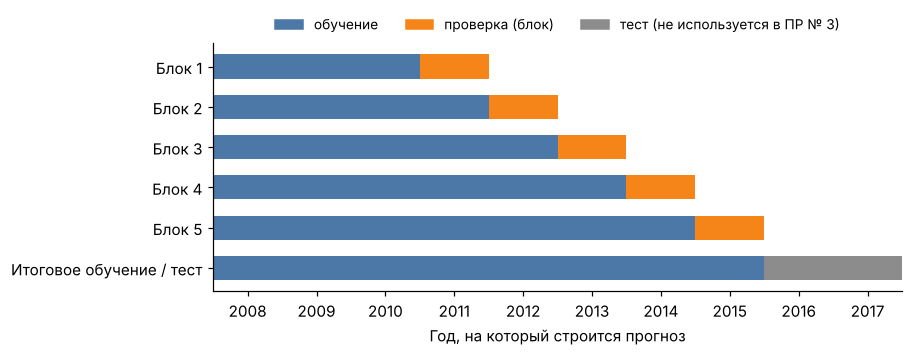

In [10]:
# Рисунок 1. Схема разбиения: блоки кросс-валидации и тест (по годам прогноза)
years = list(range(2008, 2018))
fig, ax = plt.subplots(figsize=(8.4, 3.4))
rows = [('Блок 1', 2008, 2010, 2011), ('Блок 2', 2008, 2011, 2012), ('Блок 3', 2008, 2012, 2013),
        ('Блок 4', 2008, 2013, 2014), ('Блок 5', 2008, 2014, 2015)]
for i, (lab, a, b, v) in enumerate(rows):
    yy = len(rows) - i
    ax.barh(yy, b - a + 1, left=a - 0.5, color=BLUE, height=0.6)
    ax.barh(yy, 1, left=v - 0.5, color=ORANGE, height=0.6)
ax.barh(0, 8, left=2007.5, color=BLUE, height=0.6); ax.barh(0, 2, left=2015.5, color=GRAY, height=0.6)
ax.set_yticks(range(0, 6)); ax.set_yticklabels(['Итоговое обучение / тест'] + [r[0] for r in rows][::-1])
ax.set_xticks(years); ax.set_xlim(2007.5, 2017.5)
ax.set_xlabel('Год, на который строится прогноз')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label='обучение'), Patch(color=ORANGE, label='проверка (блок)'),
                   Patch(color=GRAY, label='тест (не используется в ПР № 3)')], loc='upper center', ncol=3, frameon=False,
          bbox_to_anchor=(0.5, 1.16), fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'fig01_scheme.png', bbox_inches='tight'); plt.show()

## 3.4. Реализация пайплайна: повторяемость и отсутствие утечек

In [11]:
# Проверка повторяемости: два запуска на одних данных в идентичные таблицы признаков
X1, y1, _ = make_dataset(INITIAL); X2, y2, _ = make_dataset(INITIAL)
h1, h2 = table_hash(X1), table_hash(X2)
print('Хэш запуска 1:', h1[:24]); print('Хэш запуска 2:', h2[:24]); print('Совпадают:', h1 == h2 and table_hash(y1.to_frame()) == table_hash(y2.to_frame()))
results['repeat'] = {'hash1': h1, 'hash2': h2, 'equal': bool(h1 == h2)}

# Проверка отсутствия утечки: признаки года t не меняются, если из таблицы убрать все будущие годы
bad = {}
Xfull, _, _ = make_dataset(INITIAL)
feat_cols = [c for c in Xfull.columns if c not in ('city_key',)]
for T in (2010, 2013, 2015):
    part = pd.read_csv(INITIAL, dtype={'region_oktmo': str, 'city_oktmo': str, 'fias_code': str})
    part = part[part['year'] <= T]
    Xp, _, _ = make_dataset(part)
    a = Xfull[Xfull['year'] <= T].reset_index(drop=True)
    cmp = a[['city_key', 'year'] + [c for c in feat_cols if c not in ('year',)]].merge(
        Xp[['city_key', 'year'] + [c for c in feat_cols if c not in ('year',)]], on=['city_key', 'year'], suffixes=('_a', '_b'))
    diff = 0
    for c in feat_cols:
        if c == 'year': continue
        u, v = cmp[c + '_a'], cmp[c + '_b']
        diff += int((~((u == v) | (u.isna() & v.isna()))).sum())
    bad[T] = diff
    print(f'Обрезка по {T}: строк {len(a)}, расхождений в признаках: {diff}')
results['leak_check'] = {str(k): v for k, v in bad.items()}

Хэш запуска 1: 33470777607ff1e798537f95
Хэш запуска 2: 33470777607ff1e798537f95
Совпадают: True
Обрезка по 2010: строк 1000, расхождений в признаках: 0
Обрезка по 2013: строк 1756, расхождений в признаках: 0
Обрезка по 2015: строк 2261, расхождений в признаках: 0


In [12]:
# Функция clean и новые признаки: сколько значений изменено / какие признаки созданы
rawdf = load_raw(INITIAL); cl = clean(rawdf)
chg = {'level_-9_to_nan': int((rawdf['air_general_level'] == -9).sum()),
       'emis_out_of_range': int(sum(((pd.to_numeric(rawdf[c]) < 0) | (pd.to_numeric(rawdf[c]) > 5000)).sum() for c in EM)),
       'st_unparsed': int(cl['n_st_main'].isna().sum()), 'dups_dropped': int(len(rawdf) - len(cl))}
print(chg); results['clean_effect'] = chg
Xc = add_features(X)
new_cols = ['level_lag1', 'high_share_3y', 'n_qcp', 'n_si', 'emis_total', 'emis_per_cap', 'emis_growth', 'pop_group', 'norm_regime']
print(Xc[new_cols].describe(include='all').T[['count', 'unique', 'top', 'mean', 'min', 'max']].to_string())
results['new_features_missing_pct'] = (Xc[new_cols].isna().mean() * 100).round(1).to_dict()

{'level_-9_to_nan': 355, 'emis_out_of_range': 0, 'st_unparsed': 35, 'dups_dropped': 0}
                count unique      top       mean       min        max
level_lag1     2393.0    NaN      NaN   2.228583       1.0        4.0
high_share_3y  2478.0    NaN      NaN   0.482378       0.0        1.0
n_qcp          2748.0    NaN      NaN   1.738355       0.0        7.0
n_si           2748.0    NaN      NaN   0.164483       0.0        4.0
emis_total     2223.0    NaN      NaN  55.125723     0.024     1993.3
emis_per_cap   2220.0    NaN      NaN   0.363751  0.001285  35.428571
emis_growth    1931.0    NaN      NaN   0.301606 -0.959492        5.0
pop_group        2617      5      <50        NaN       NaN        NaN
norm_regime      2748      2  до 2014        NaN       NaN        NaN


## 3.5. Базовое решение

In [13]:
# Реестр результатов экспериментов
EXP = []
def run(label, family, spec, fs='C', raw=False):
    mdl = mark_raw(spec) if raw else build_model(spec[0], **spec[1])
    r = cv_evaluate(mdl, Xtr, ytr, folds, fs, label)
    r.update({'family': family, 'spec': None if raw else {'name': spec[0], 'params': spec[1]}, 'feature_set': fs})
    EXP.append(r); return r
def show(r):
    print(f"{r['model']:<44} ROC-AUC {r['roc_auc_mean']:.3f}±{r['roc_auc_std']:.3f} | PR-AUC {r['pr_auc_mean']:.3f} | "
          f"macroF1 {r['macro_f1_mean']:.3f} | QWK {r['qwk_mean']:.3f} | Recall {r['recall_high_mean']:.3f} | {r['fit_time_s']:.2f} c")
show(run('Наиболее частый класс', 'baseline', ('dummy', {})))
show(run('Правило: уровень года t+1 = уровню года t', 'baseline', PersistenceClassifier(), raw=True))
print('Доля уровней 3–4 среди целей обучающей выборки:', round((ytr >= 3).mean(), 3))

Наиболее частый класс                        ROC-AUC 0.500±0.000 | PR-AUC 0.445 | macroF1 0.120 | QWK 0.000 | Recall 1.000 | 0.02 c
Правило: уровень года t+1 = уровню года t    ROC-AUC 0.845±0.073 | PR-AUC 0.721 | macroF1 0.649 | QWK 0.745 | Recall 0.925 | 0.00 c
Доля уровней 3–4 среди целей обучающей выборки: 0.506


## 3.6. Линейные модели: L1 и L2

           auc        nonzero      
penalty     L1     L2      L1    L2
C                                  
0.001    0.500  0.911     0.0  32.0
0.003    0.658  0.927     1.0  32.0
0.010    0.921  0.936     5.0  32.0
0.030    0.944  0.940    14.0  32.0
0.100    0.946  0.941    19.0  32.0
0.300    0.942  0.941    26.0  32.0
1.000    0.939  0.939    30.0  32.0
3.000    0.938  0.937    32.0  32.0
10.000   0.938  0.937    32.0  32.0
100.000  0.937  0.937    32.0  32.0


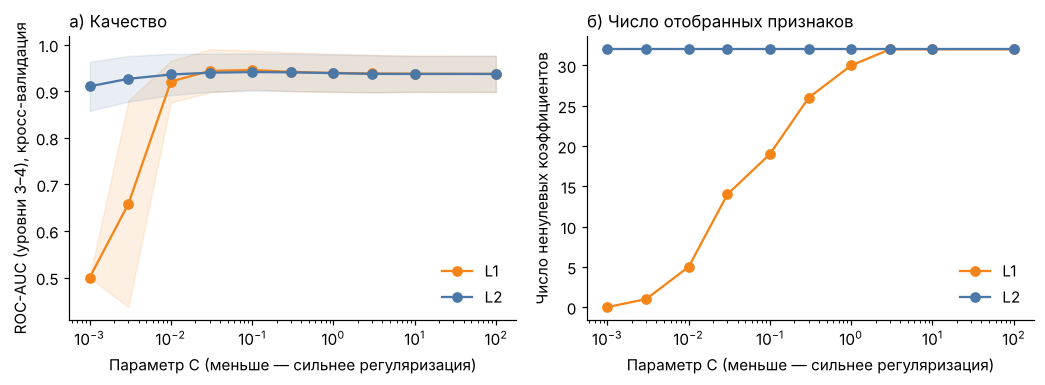

In [14]:
# Рисунок 2. Влияние силы регуляризации на ROC-AUC и число ненулевых коэффициентов
Cs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
reg = []
for pen in ['logreg_l1', 'logreg_l2']:
    for Cv in Cs:
        r = cv_evaluate(build_model(pen, C=Cv), Xtr, ytr, folds, 'C', pen)
        pipe = make_pipeline(build_model(pen, C=Cv), 'C').fit(Xtr, ytr)
        coef = pipe['model'].coef_
        nz = int((np.abs(coef).max(axis=0) > 1e-8).sum())
        reg.append({'penalty': pen[-2:].upper(), 'C': Cv, 'auc': r['roc_auc_mean'], 'sd': r['roc_auc_std'], 'nonzero': nz, 'n_features': coef.shape[1]})
reg = pd.DataFrame(reg); results['reg_path'] = reg.to_dict('records')
print(reg.pivot(index='C', columns='penalty', values=['auc', 'nonzero']).round(3).to_string())
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.6))
for pen, col in [('L1', ORANGE), ('L2', BLUE)]:
    d = reg[reg.penalty == pen]
    axs[0].plot(d['C'], d['auc'], marker='o', color=col, label=pen)
    axs[0].fill_between(d['C'], d['auc'] - d['sd'], d['auc'] + d['sd'], color=col, alpha=0.12)
    axs[1].plot(d['C'], d['nonzero'], marker='o', color=col, label=pen)
for a in axs: a.set_xscale('log'); a.set_xlabel('Параметр C (меньше — сильнее регуляризация)')
axs[0].set_ylabel('ROC-AUC (уровни 3–4), кросс-валидация'); axs[1].set_ylabel('Число ненулевых коэффициентов')
axs[0].set_title('а) Качество', loc='left'); axs[1].set_title('б) Число отобранных признаков', loc='left')
axs[0].legend(frameon=False); axs[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'fig02_regularization.png', bbox_inches='tight'); plt.show()

In [15]:
# Модели для таблицы: L2 (C = 1) и L1 (C = 0.1); коэффициенты L2-модели
show(run('Логистическая регрессия, L2 (C = 1)', 'logreg', ('logreg_l2', {'C': 1.0})))
show(run('Логистическая регрессия, L1 (C = 0.1)', 'logreg', ('logreg_l1', {'C': 0.1})))
pipe = make_pipeline(build_model('logreg_l2', C=1.0), 'C').fit(Xtr, ytr)
names = [n.split('__', 1)[1] for n in pipe['prep'].get_feature_names_out()]
coef = pd.DataFrame(pipe['model'].coef_.T, index=names, columns=['уровень 1', 'уровень 2', 'уровень 3', 'уровень 4'])
print('Признаков после предобработки:', len(names))
top4 = coef['уровень 4'].sort_values(); top1 = coef['уровень 1'].sort_values()
results['coef_top'] = {'level4_pos': top4.tail(6).round(2).to_dict(), 'level4_neg': top4.head(4).round(2).to_dict(),
                       'level1_pos': top1.tail(5).round(2).to_dict(), 'level1_neg': top1.head(4).round(2).to_dict(),
                       'n_features': len(names)}
print(coef.round(2).reindex(coef['уровень 4'].abs().sort_values(ascending=False).index).head(10).to_string())

Логистическая регрессия, L2 (C = 1)          ROC-AUC 0.939±0.040 | PR-AUC 0.906 | macroF1 0.610 | QWK 0.744 | Recall 0.855 | 0.04 c
Логистическая регрессия, L1 (C = 0.1)        ROC-AUC 0.946±0.042 | PR-AUC 0.915 | macroF1 0.621 | QWK 0.748 | Recall 0.893 | 0.11 c
Признаков после предобработки: 32
                       уровень 1  уровень 2  уровень 3  уровень 4
level_lag1                 -2.06      -0.64      -0.00       2.70
norm_regime_2014-2020       1.25       0.43      -0.71      -0.98
high_share_3y              -0.53      -0.65       0.26       0.93
norm_regime_до 2014        -1.24      -0.41       0.73       0.91
n_qcp                      -0.89      -0.05       0.35       0.59
geo_lon                    -0.34      -0.29       0.19       0.44
air_population             -0.50       0.08       0.03       0.38
pop_group_50-100           -0.07       0.03      -0.29       0.32
n_si                       -0.38      -0.07       0.15       0.30
pop_group_>=500            -0.22      -0.0

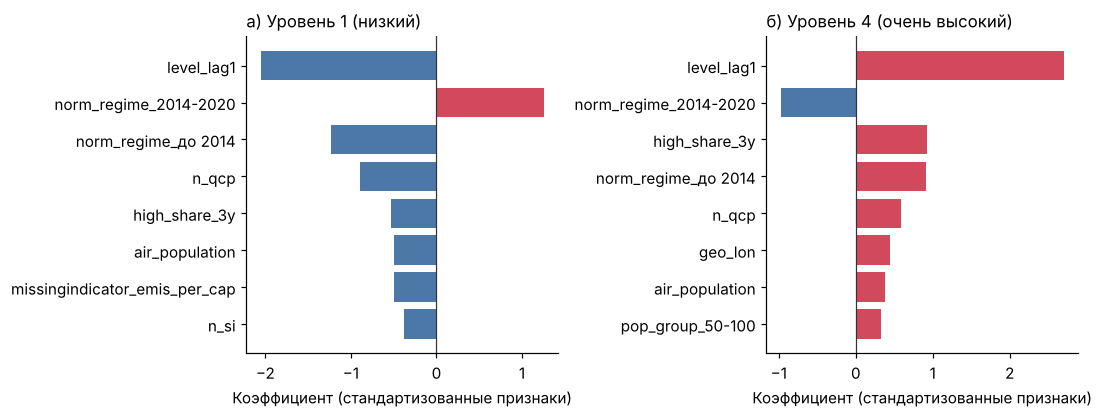

In [16]:
# Рисунок 3. Наибольшие коэффициенты L2-модели для уровней 1 и 4
fig, axs = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, col, ttl in [(axs[0], 'уровень 1', 'а) Уровень 1 (низкий)'), (axs[1], 'уровень 4', 'б) Уровень 4 (очень высокий)')]:
    s = coef[col]; s = s.reindex(s.abs().sort_values(ascending=False).index).head(8)[::-1]
    ax.barh(s.index, s.values, color=[RED if v > 0 else BLUE for v in s.values])
    ax.axvline(0, color='#333', lw=0.8); ax.set_xlabel('Коэффициент (стандартизованные признаки)'); ax.set_title(ttl, loc='left')
plt.tight_layout(); plt.savefig(FIG / 'fig03_coefficients.png', bbox_inches='tight'); plt.show()

## 3.7. Модели классификации и ансамбли

 depth  train   val  val_sd
     1  0.769 0.706   0.060
     2  0.827 0.802   0.047
     3  0.920 0.903   0.044
     4  0.935 0.905   0.034
     5  0.948 0.895   0.034
     6  0.955 0.894   0.049
     7  0.962 0.864   0.063
     8  0.971 0.835   0.070
     9  0.978 0.838   0.050
    10  0.986 0.843   0.060
    11  0.991 0.813   0.062
    12  0.995 0.806   0.080
    13  0.997 0.810   0.066
    14  0.999 0.816   0.058
    15  0.999 0.812   0.059
    16  1.000 0.810   0.064
Лучшая глубина: 4


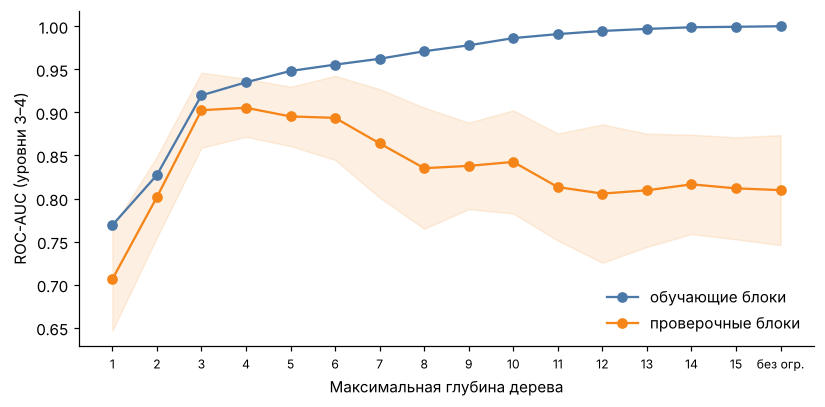

In [17]:
# Рисунок 4. Дерево решений: качество на обучающих и проверочных данных в зависимости от глубины
from sklearn.base import clone
depths = list(range(1, 16)) + [None]
rows = []
for dpt in depths:
    trs, vas = [], []
    for tr, va in folds:
        est = make_pipeline(build_model('tree', max_depth=dpt), 'C').fit(Xtr.iloc[tr], ytr.iloc[tr])
        trs.append(metrics(ytr.iloc[tr], full_proba(est, Xtr.iloc[tr]))['roc_auc'])
        vas.append(metrics(ytr.iloc[va], full_proba(est, Xtr.iloc[va]))['roc_auc'])
    rows.append({'depth': 16 if dpt is None else dpt, 'train': np.mean(trs), 'val': np.mean(vas), 'val_sd': np.std(vas, ddof=1)})
dd = pd.DataFrame(rows); results['tree_depth'] = dd.to_dict('records')
best_depth = int(dd.loc[dd['val'].idxmax(), 'depth'])
print(dd.round(3).to_string(index=False)); print('Лучшая глубина:', best_depth)
fig, ax = plt.subplots(figsize=(7.6, 3.8))
ax.plot(dd['depth'], dd['train'], marker='o', color=BLUE, label='обучающие блоки')
ax.plot(dd['depth'], dd['val'], marker='o', color=ORANGE, label='проверочные блоки')
ax.fill_between(dd['depth'], dd['val'] - dd['val_sd'], dd['val'] + dd['val_sd'], color=ORANGE, alpha=0.12)
ax.set_xticks(dd['depth']); ax.set_xticklabels([str(d) for d in dd['depth'][:-1]] + ['без огр.'], fontsize=8)
ax.set_xlabel('Максимальная глубина дерева'); ax.set_ylabel('ROC-AUC (уровни 3–4)'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / 'fig04_tree_depth.png', bbox_inches='tight'); plt.show()

In [18]:
# Остальные семейства со стандартными параметрами
show(run(f'Дерево решений (глубина {best_depth})', 'tree', ('tree', {'max_depth': best_depth})))
show(run('Дерево решений без ограничения глубины', 'tree', ('tree', {})))
show(run('k ближайших соседей (k = 25)', 'knn', ('knn', {'n_neighbors': 25})))
show(run('Метод опорных векторов (RBF, C = 1)', 'svm', ('svm', {})))
show(run('Наивный байесовский классификатор', 'nb', ('nb', {})))
show(run('Случайный лес (300 деревьев)', 'rf', ('rf', {})))
show(run('Градиентный бустинг (по умолчанию)', 'hgb', ('hgb', {})))

Дерево решений (глубина 4)                   ROC-AUC 0.905±0.034 | PR-AUC 0.822 | macroF1 0.607 | QWK 0.732 | Recall 0.818 | 0.02 c
Дерево решений без ограничения глубины       ROC-AUC 0.810±0.064 | PR-AUC 0.680 | macroF1 0.570 | QWK 0.683 | Recall 0.858 | 0.02 c
k ближайших соседей (k = 25)                 ROC-AUC 0.896±0.084 | PR-AUC 0.797 | macroF1 0.512 | QWK 0.653 | Recall 0.932 | 0.02 c
Метод опорных векторов (RBF, C = 1)          ROC-AUC 0.933±0.046 | PR-AUC 0.890 | macroF1 0.622 | QWK 0.747 | Recall 0.907 | 0.18 c
Наивный байесовский классификатор            ROC-AUC 0.896±0.031 | PR-AUC 0.832 | macroF1 0.271 | QWK 0.518 | Recall 0.591 | 0.02 c
Случайный лес (300 деревьев)                 ROC-AUC 0.928±0.051 | PR-AUC 0.866 | macroF1 0.621 | QWK 0.743 | Recall 0.881 | 0.56 c
Градиентный бустинг (по умолчанию)           ROC-AUC 0.915±0.053 | PR-AUC 0.853 | macroF1 0.607 | QWK 0.721 | Recall 0.899 | 0.70 c


## 3.8. Польза новых признаков
A — исходные столбцы года *t*; B — A + история города (уровень, доля высоких лет, число веществ); C — B + суммарные выбросы, выбросы на жителя, прирост, группа населения, нормативный режим; D — C + регион.

                       model set   auc    sd    f1   qwk
Логистическая регрессия (L2)   A 0.769 0.044 0.301 0.308
Логистическая регрессия (L2)   B 0.940 0.039 0.618 0.735
Логистическая регрессия (L2)   C 0.939 0.040 0.610 0.744
Логистическая регрессия (L2)   D 0.934 0.048 0.618 0.736
         Градиентный бустинг   A 0.894 0.064 0.580 0.661
         Градиентный бустинг   B 0.922 0.051 0.613 0.721
         Градиентный бустинг   C 0.915 0.053 0.607 0.721
         Градиентный бустинг   D 0.918 0.053 0.621 0.737


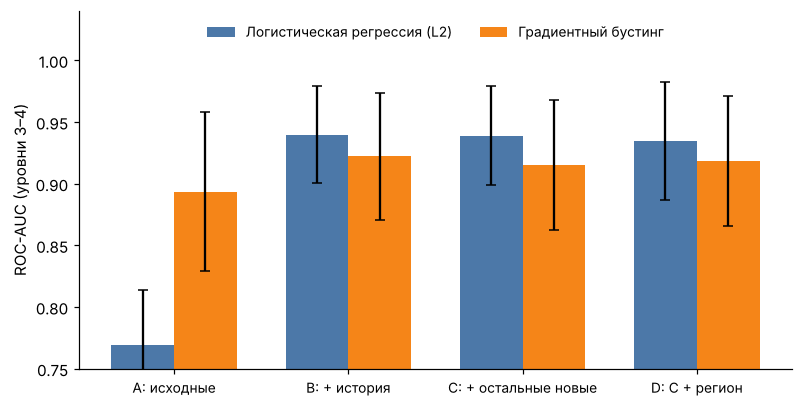

In [19]:
# Рисунок 5. Качество на наборах признаков A, B, C, D
abl = []
for nm, spec in [('Логистическая регрессия (L2)', ('logreg_l2', {'C': 1.0})), ('Градиентный бустинг', ('hgb', {}))]:
    for fs in 'ABCD':
        r = cv_evaluate(build_model(spec[0], **spec[1]), Xtr, ytr, folds, fs, nm)
        abl.append({'model': nm, 'set': fs, 'auc': r['roc_auc_mean'], 'sd': r['roc_auc_std'], 'f1': r['macro_f1_mean'], 'qwk': r['qwk_mean']})
abl = pd.DataFrame(abl); results['ablation'] = abl.to_dict('records')
print(abl.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7.4, 3.8)); w = 0.36
for j, (nm, col) in enumerate([('Логистическая регрессия (L2)', BLUE), ('Градиентный бустинг', ORANGE)]):
    d = abl[abl.model == nm]
    ax.bar(np.arange(4) + (j - 0.5) * w, d['auc'], w, yerr=d['sd'], color=col, capsize=3, label=nm)
ax.set_xticks(range(4)); ax.set_xticklabels(['A: исходные', 'B: + история', 'C: + остальные новые', 'D: C + регион'], fontsize=9)
ax.set_ylim(0.75, 1.04); ax.set_ylabel('ROC-AUC (уровни 3–4)'); ax.legend(frameon=False, loc='upper center', ncol=2, fontsize=9)
plt.tight_layout(); plt.savefig(FIG / 'fig05_feature_sets.png', bbox_inches='tight'); plt.show()

## 3.9. Подбор гиперпараметров
Подбираются гиперпараметры двух лучших по ROC-AUC семейств; перебор — `GridSearchCV` с теми же годовыми блоками. Это та же кросс-валидация, поэтому оценка слегка оптимистична; независимая проверка — на тесте в практической работе № 4.

In [20]:
from sklearn.model_selection import GridSearchCV
GRIDS = {
 'logreg_l2': {'C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30], 'class_weight': [None, 'balanced']},
 'logreg_l1': {'C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30], 'class_weight': [None, 'balanced']},
 'hgb': {'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4, None], 'max_iter': [100, 200, 300], 'min_samples_leaf': [20, 50]},
 'rf': {'max_depth': [None, 8, 12], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]},
 'svm': {'C': [0.3, 1, 3, 10], 'gamma': ['scale', 0.01, 0.03]},
 'knn': {'n_neighbors': [5, 10, 15, 25, 40, 60], 'weights': ['uniform', 'distance']},
 'tree': {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [1, 5, 10, 20]},
}
df_exp = pd.DataFrame([e for e in EXP if e['family'] != 'baseline'])
best_by_family = df_exp.sort_values('roc_auc_mean', ascending=False).drop_duplicates('family')
top2 = best_by_family.head(2)
print('Лучшие семейства (по ROC-AUC):'); print(top2[['model', 'roc_auc_mean']].round(3).to_string(index=False))
tuning = []
for _, row in top2.iterrows():
    name, base_params = row['spec']['name'], row['spec']['params']
    grid = GRIDS[name]; n_comb = int(np.prod([len(v) for v in grid.values()]))
    gs = GridSearchCV(make_pipeline(build_model(name, **base_params), 'C'), {f'model__{k}': v for k, v in grid.items()},
                      scoring=high_auc_scorer, cv=folds, refit=False, n_jobs=1)
    t0 = time.time(); gs.fit(Xtr, ytr)
    best = {k.replace('model__', ''): (None if v is None else v) for k, v in gs.best_params_.items()}
    params = {**base_params, **best}
    r = run(row['model'].split(' (')[0] + ' (после подбора)', row['family'], (name, params))
    show(r)
    tuning.append({'model': row['model'], 'name': name, 'grid': {k: [str(x) for x in v] for k, v in grid.items()}, 'n_comb': n_comb,
                   'best': {k: str(v) for k, v in best.items()}, 'auc_before': float(row['roc_auc_mean']), 'auc_after': r['roc_auc_mean'],
                   'search_time_s': round(time.time() - t0, 1)})
    print(name, 'комбинаций:', n_comb, '| лучший набор:', best)
results['tuning'] = tuning

Лучшие семейства (по ROC-AUC):
                                model  roc_auc_mean
Логистическая регрессия, L1 (C = 0.1)         0.946
  Метод опорных векторов (RBF, C = 1)         0.933
Логистическая регрессия, L1 (после подбора)  ROC-AUC 0.946±0.041 | PR-AUC 0.919 | macroF1 0.649 | QWK 0.767 | Recall 0.923 | 0.06 c
logreg_l1 комбинаций: 16 | лучший набор: {'C': 0.03, 'class_weight': 'balanced'}
Метод опорных векторов (после подбора)       ROC-AUC 0.943±0.034 | PR-AUC 0.914 | macroF1 0.613 | QWK 0.746 | Recall 0.931 | 0.20 c
svm комбинаций: 12 | лучший набор: {'C': 0.3, 'gamma': 0.01}


## 3.10. Сводная таблица, выбор и сохранение итоговой модели
**Правило выбора:** наибольший средний ROC-AUC; если модели отличаются меньше чем на 0,005 — берётся более простая и быстрая (порядок сложности задан в `COMPLEXITY`).

In [21]:
# Таблица экспериментов и выбор итоговой модели
exp = pd.DataFrame(EXP)
Path('reports').mkdir(exist_ok=True)
exp.drop(columns=['spec']).to_csv('reports/experiments.csv', index=False, encoding='utf-8')
cand = exp[exp['family'] != 'baseline'].copy()
best_auc = cand['roc_auc_mean'].max()
near = cand[cand['roc_auc_mean'] >= best_auc - 0.005].copy()
fam_rank = {n: i for i, n in enumerate(COMPLEXITY)}
near['rank'] = near['spec'].apply(lambda s: fam_rank[s['name']])
chosen = near.sort_values(['rank', 'fit_time_s']).iloc[0]
print('Лучший ROC-AUC:', round(best_auc, 3), '| кандидатов в пределах 0.005:', len(near))
print('Итоговая модель:', chosen['model'], chosen['spec'])
results['selection'] = {'best_auc': float(best_auc), 'n_near': int(len(near)), 'near': near['model'].tolist(),
                        'chosen': chosen['model'], 'spec': chosen['spec'], 'chosen_auc': float(chosen['roc_auc_mean'])}
print(exp[['model', 'roc_auc_mean', 'roc_auc_std', 'pr_auc_mean', 'macro_f1_mean', 'qwk_mean', 'recall_high_mean', 'fit_time_s']].round(3).to_string(index=False))
results['experiments'] = exp.drop(columns=['spec']).to_dict('records')

Лучший ROC-AUC: 0.946 | кандидатов в пределах 0.005: 3
Итоговая модель: Логистическая регрессия, L1 (после подбора) {'name': 'logreg_l1', 'params': {'C': 0.03, 'class_weight': 'balanced'}}
                                      model  roc_auc_mean  roc_auc_std  pr_auc_mean  macro_f1_mean  qwk_mean  recall_high_mean  fit_time_s
                      Наиболее частый класс         0.500        0.000        0.445          0.120     0.000             1.000       0.023
  Правило: уровень года t+1 = уровню года t         0.845        0.073        0.721          0.649     0.745             0.925       0.001
        Логистическая регрессия, L2 (C = 1)         0.939        0.040        0.906          0.610     0.744             0.855       0.036
      Логистическая регрессия, L1 (C = 0.1)         0.946        0.042        0.915          0.621     0.748             0.893       0.107
                 Дерево решений (глубина 4)         0.905        0.034        0.822          0.607     0.732        

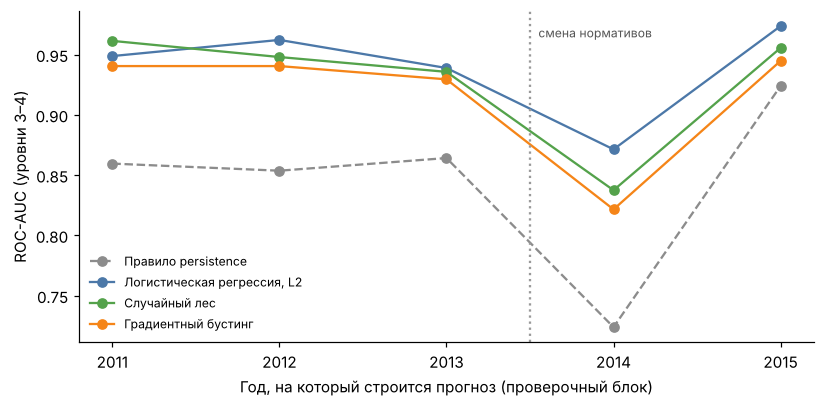

In [22]:
# Рисунок 6. ROC-AUC по проверочным блокам (годам) — как ведут себя модели при смене нормативов в 2014 году
sel = {'Правило: уровень года t+1 = уровню года t': ('Правило persistence', GRAY, '--'),
       'Логистическая регрессия, L2 (C = 1)': ('Логистическая регрессия, L2', BLUE, '-'),
       'Случайный лес (300 деревьев)': ('Случайный лес', GREEN, '-'),
       'Градиентный бустинг (по умолчанию)': ('Градиентный бустинг', ORANGE, '-')}
fig, ax = plt.subplots(figsize=(7.6, 3.8))
for key, (lab, col, ls) in sel.items():
    r = exp[exp['model'] == key].iloc[0]
    ax.plot(CV_VAL_YEARS, r['roc_auc_folds'], marker='o', color=col, ls=ls, label=lab)
ax.axvline(2013.5, color='#999', ls=':'); ax.text(2013.55, ax.get_ylim()[1] - 0.012, 'смена нормативов', fontsize=8, color='#555', va='top')
ax.set_xticks(CV_VAL_YEARS); ax.set_xlabel('Год, на который строится прогноз (проверочный блок)'); ax.set_ylabel('ROC-AUC (уровни 3–4)')
ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(FIG / 'fig06_folds.png', bbox_inches='tight'); plt.show()

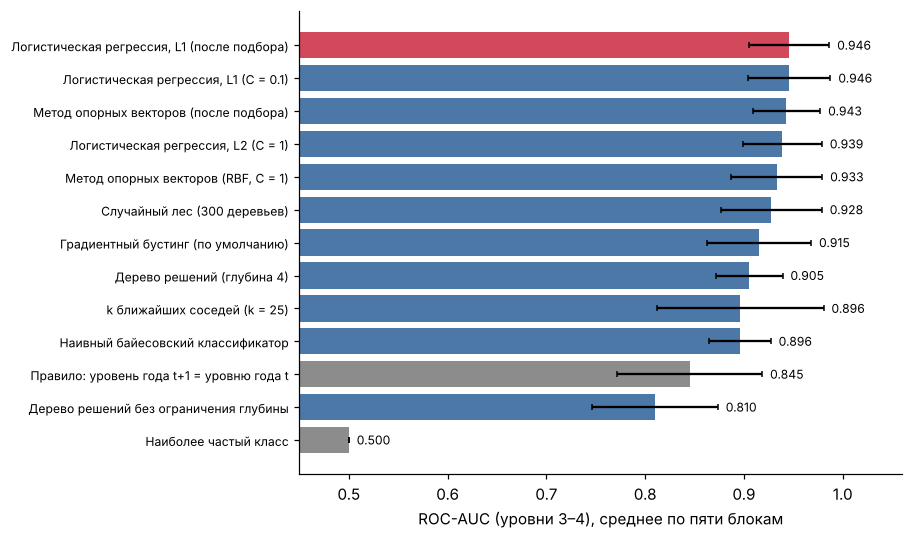

In [23]:
# Рисунок 7. Сравнение моделей по ROC-AUC (среднее и стандартное отклонение по пяти блокам)
d = exp.sort_values('roc_auc_mean')
colors = [GRAY if f == 'baseline' else (RED if m == chosen['model'] else BLUE) for f, m in zip(d['family'], d['model'])]
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.barh(d['model'], d['roc_auc_mean'], xerr=d['roc_auc_std'], color=colors, capsize=2)
for i, (v, e) in enumerate(zip(d['roc_auc_mean'], d['roc_auc_std'])): ax.text(v + e + 0.008, i, f'{v:.3f}', va='center', fontsize=8)
ax.set_xlim(0.45, 1.06); ax.set_xlabel('ROC-AUC (уровни 3–4), среднее по пяти блокам'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig07_comparison.png', bbox_inches='tight'); plt.show()

In [24]:
# Обучение итоговой модели скриптом src/models/train.py (ячейка записывает выбранную конфигурацию и вызывает main)
import joblib
from src.models.train import main as train_main
spec = chosen['spec']
sel = {'name': spec['name'], 'params': spec['params'], 'feature_set': 'C', 'trained': '2026-11-11',
       'cv_roc_auc': round(float(chosen['roc_auc_mean']), 3), 'cv_roc_auc_std': round(float(chosen['roc_auc_std']), 3),
       'cv_pr_auc': round(float(chosen['pr_auc_mean']), 3), 'cv_macro_f1': round(float(chosen['macro_f1_mean']), 3),
       'cv_qwk': round(float(chosen['qwk_mean']), 3), 'cv_recall_high': round(float(chosen['recall_high_mean']), 3),
       'selection_rule': 'максимум среднего ROC-AUC; при разнице < 0.005 — более простая модель'}
json.dump(sel, open('models/selected_model.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
final, info = train_main()
chk = joblib.load('models/model_v1.joblib')
same = bool(np.allclose(chk.predict_proba(Xtr), final.predict_proba(Xtr)))
final2, _ = train_main()
same2 = bool(np.allclose(final2.predict_proba(Xtr), final.predict_proba(Xtr)))
print('Модель сохранена: models/model_v1.joblib, размер', Path('models/model_v1.joblib').stat().st_size, 'байт')
print('Алгоритм:', info['algorithm'])
print('Загруженная модель даёт те же вероятности:', same, '| повторный запуск скрипта даёт те же вероятности:', same2)
results['final'] = {'info': info, 'reload_same': same, 'retrain_same': same2, 'size_bytes': Path('models/model_v1.joblib').stat().st_size}

Модель сохранена: models/model_v1.joblib, размер 9106 байт
Алгоритм: logreg_l1 {'C': 0.03, 'class_weight': 'balanced'}
Загруженная модель даёт те же вероятности: True | повторный запуск скрипта даёт те же вероятности: True


In [25]:
# Какие признаки оставила L1-регуляризация итоговой модели
names = [n.split('__', 1)[1] for n in final['prep'].get_feature_names_out()]
cf = pd.DataFrame(final['model'].coef_.T, index=names, columns=['уровень 1', 'уровень 2', 'уровень 3', 'уровень 4'])
nzmask = cf.abs().max(axis=1) > 1e-8
print('Ненулевых коэффициентов:', int(nzmask.sum()), 'из', len(names))
print('Обнулены:', ', '.join(sorted(cf.index[~nzmask])))
strong = cf[nzmask].assign(m=cf[nzmask].abs().max(axis=1)).sort_values('m', ascending=False).drop(columns='m').round(2)
print(strong.head(10).to_string())
results['final_coef'] = {'nonzero': int(nzmask.sum()), 'total': len(names), 'zeroed': sorted(cf.index[~nzmask]),
                         'top': strong.head(10).to_dict('index')}

Ненулевых коэффициентов: 14 из 32
Обнулены: air_so_emissions, emis_growth, emis_total, geo_lat, missingindicator_air_co_emissions, missingindicator_air_no_emissions, missingindicator_air_population, missingindicator_air_so_emissions, missingindicator_air_solid_emissions, missingindicator_emis_growth, missingindicator_emis_per_cap, missingindicator_emis_total, n_st_main, pop_group_100-250, pop_group_250-500, pop_group_50-100, pop_group_<50, pop_group_>=500
                             уровень 1  уровень 2  уровень 3  уровень 4
level_lag1                       -1.33       0.00       0.00       2.44
n_qcp                            -0.65       0.00       0.05       0.07
high_share_3y                     0.00      -0.36       0.63       0.00
norm_regime_до 2014              -0.21       0.00       0.36       0.00
missingindicator_level_lag1       0.24       0.00       0.00       0.00
norm_regime_2014-2020             0.21       0.00      -0.06       0.00
geo_lon                           0.

In [26]:
# Проверка применимости пайплайна к новым порциям (без оценки качества): те же шаги, та же сохранённая модель
hist_raw = load_raw(INITIAL); batch_report = []
for i in range(1, 5):
    bp = Path(f'data/incoming/batch_{i:02d}.csv')
    if not bp.exists():
        raw = pd.read_csv(RAW, encoding='utf-8-sig', dtype=str); Path('data/incoming').mkdir(exist_ok=True)
        for k, (a, b) in enumerate([(2018, 2019), (2020, 2021), (2022, 2023), (2024, 2024)], 1):
            raw[(raw['year'].astype(int) >= a) & (raw['year'].astype(int) <= b)].to_csv(f'data/incoming/batch_{k:02d}.csv', index=False)
    bat = load_raw(bp)
    Xb, _, mb = make_dataset(bat, history=hist_raw)
    p = chk.predict_proba(Xb)
    ph = p[:, 2:].sum(axis=1)
    batch_report.append({'batch': bp.name, 'rows': len(Xb), 'years': f"{int(Xb['year'].min())}–{int(Xb['year'].max())}",
                         'with_history_pct': round(float(Xb['level_lag1'].notna().mean() * 100), 1),
                         'share_high_pred_pct': round(float((ph >= 0.5).mean() * 100), 1)})
    hist_raw = pd.concat([hist_raw, bat], ignore_index=True)
print(pd.DataFrame(batch_report).to_string(index=False)); results['batches'] = batch_report

       batch  rows     years  with_history_pct  share_high_pred_pct
batch_01.csv   496 2018–2019              88.9                 14.7
batch_02.csv   499 2020–2021              91.4                 17.2
batch_03.csv   490 2022–2023              93.7                 37.6
batch_04.csv   246 2024–2024              95.5                 41.5


In [27]:
# Сохранение чисел для отчёта
def _j(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    return str(o)
Path('reports').mkdir(exist_ok=True)
Path('reports/results_pr3.json').write_text(json.dumps(results, ensure_ascii=False, indent=1, default=_j), encoding='utf-8')
print('Готово. Рисунки:'); print(*sorted(p.name for p in FIG.glob('*.png')), sep='\n')

Готово. Рисунки:
fig01_scheme.png
fig02_regularization.png
fig03_coefficients.png
fig04_tree_depth.png
fig05_feature_sets.png
fig06_folds.png
fig07_comparison.png
